# P-1-1: geometry tracking versus reviewed identity

One recording, three fish, seven inherited lambda settings. These results measure
agreement with the supplied human-reviewed F/M1/M2 labels. They do not independently
validate 3D positions or establish an error rate for other fish groups.

In [1]:
import json
import sys
import tomllib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import medaka3d
from medaka3d import load_paths

matplotlib.use("module://matplotlib_inline.backend_inline")
repo = Path(medaka3d.__file__).resolve().parents[2]
assert Path(sys.prefix).resolve() == (repo / ".venv").resolve(), (
    "Use the project virtual environment"
)
analysis = repo / "analyses/20261031_p11_identity_evaluation"
config = tomllib.loads((analysis / "config.toml").read_text(encoding="utf-8-sig"))
paths = load_paths()
run = paths.raw_data_dir.parent / config["output"]["relative_to_data_parent"] / config["run_id"]
score = run / config["evaluation"]["primary_scoring_directory"]
assert json.loads((run / "run_status.json").read_text())["status"] == "complete"
summary = pd.read_csv(score / "identity_summary.csv")
inventory = json.loads((score / "reference_inventory.json").read_text())
arm_results = json.loads((score / "arm_results.json").read_text())
validation = json.loads((score / "validation.json").read_text())
anchors = json.loads((score / "anchor_mappings.json").read_text())
primary = summary[
    summary.match_distance_mm.eq(config["evaluation"]["max_match_distance_mm"])
].copy()
overview = primary.groupby("lambda_mm").agg(
    correct_seconds=("correct_id_seconds", "sum"),
    wrong_seconds=("wrong_id_seconds", "sum"),
    expected_seconds=("expected_seconds", "sum"),
)
overview["scored_seconds"] = overview.correct_seconds + overview.wrong_seconds
overview["agreement_percent"] = 100 * overview.correct_seconds / overview.scored_seconds
overview["correct_time_percent"] = 100 * overview.correct_seconds / overview.expected_seconds
overview["scored_time_percent"] = 100 * overview.scored_seconds / overview.expected_seconds
overview["joint_correct_percent"] = [
    100 * arm_results[f"{x:g}"]["joint_correct_fraction"] for x in overview.index
]
shown = config["evaluation"]["display_lambda"]
shown_rows = (
    primary[primary.lambda_mm.eq(shown)].set_index("reference_label").loc[["F", "M1", "M2"]]
)
figures = run / "figures"
figures.mkdir(exist_ok=True)
colors = {"correct": "#2878A3", "wrong": "#C56428", "unscored": "#C3C6CA"}
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 120,
        "savefig.dpi": 150,
    }
)


def save_figure(fig, name):
    fig.savefig(figures / name, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


print(
    f"Recording: {config['experiment']}; execution: {config['run_id']}; "
    f"Python {sys.version.split()[0]}"
)

Recording: 20260112_P_1_1_FCMC; execution: id_evaluation_20261031_r2; Python 3.13.11


In [2]:
fish_lines = "; ".join(
    f"{label}: {row.id_agreement_on_scored_time:.2%}" for label, row in shown_rows.iterrows()
)
display(
    Markdown(
        "**Fresh rerun completed for all seven conditions.** "
        "The historically displayed condition "
        f"lambda={shown:g} agrees with reviewed IDs over scored time as follows: {fish_lines}. "
        "All three fish agree simultaneously over "
        f"{overview.loc[shown, 'joint_correct_percent']:.2f}% "
        f"of the full post-preparation duration. Lambda={shown:g} is shown "
        "for continuity with earlier "
        "reports, not selected as a validated optimum. All conditions are shown below."
    )
)

**Fresh rerun completed for all seven conditions.** The historically displayed condition lambda=0.767 agrees with reviewed IDs over scored time as follows: F: 98.78%; M1: 76.35%; M2: 77.34%. All three fish agree simultaneously over 74.26% of the full post-preparation duration. Lambda=0.767 is shown for continuity with earlier reports, not selected as a validated optimum. All conditions are shown below.

## Context and methods

- Existing S14 detections were verified against all supplied per-camera SLEAP instances.
  C27, C28, C33, C30 v4, and C34 were rerun. Each camera and each Viterbi sequence is
  serial in time. Independent lambda arms run in separate processes.
- Use native acquisition timestamps and exclude the first 300 seconds. A fixed identity
  anchor at [298, 300) seconds maps slots to reference labels once.
  Never remap after a crossing.
- Match pectoral positions without using identity labels: mutual nearest positions within
  5 mm and a 2 mm margin against competing positions. Repeat at 2 and 10 mm for sensitivity.
- Exclude unviewed, uncertain, bad3d, nodes_bad, interpolated, and nonfinite reference positions
  from correctness scoring. Retain their time in the full coverage denominator.
- `watched` means displayed at any speed. `uncertain` was unused. Neither flag proves that
  every short identity exchange was resolved. The reference shares underlying geometry
  with the pipeline, so small coordinate error is not independent spatial validation.
- Report observational agreement for one trio. No framewise independence assumption,
  biological replication claim, or population-level confidence interval is made.

In [3]:
display(
    pd.DataFrame(
        [
            {
                "First scored frame": inventory["first_scored_frame"],
                "First scored time (s)": inventory["first_scored_time_s"],
                "Last acquisition (s)": inventory["recording_end_s"],
                "Expected fish-time (s)": inventory["expected_fish_seconds"],
                "Reference eligible fish-time (s)": inventory["reference_eligible_fish_seconds"],
            }
        ]
    ).round(6)
)
display(
    Markdown(
        "Elapsed camera clocks differ by at most 3.51 ms at the same native index. "
        "The existing camera index alignment is retained; absolute hardware synchronization "
        "has not been independently re-established. Durations use left-held intervals ending "
        "at the next acquisition, with no extrapolation beyond the last timestamp."
    )
)

,First scored frame,First scored time (s),Last acquisition (s),Expected fish-time (s),Reference eligible fish-time (s)
0,49794,300.002279,2100.265586,5400.796757,5368.701428


Elapsed camera clocks differ by at most 3.51 ms at the same native index. The existing camera index alignment is retained; absolute hardware synchronization has not been independently re-established. Durations use left-held intervals ending at the next acquisition, with no extrapolation beyond the last timestamp.

## Results across all conditions

,Agreement on scored time (%),Scored time / expected (%),Correct ID time / expected (%),All three correct / recording time (%)
lambda_mm,,,,
0.000,38.73,98.87,38.29,17.62
0.100,27.27,98.86,26.96,15.05
0.250,49.83,98.86,49.26,29.32
0.500,45.02,98.86,44.51,24.59
0.767,84.11,98.85,83.14,74.26
2.000,19.72,98.84,19.49,11.68
8.000,22.52,98.79,22.25,11.67


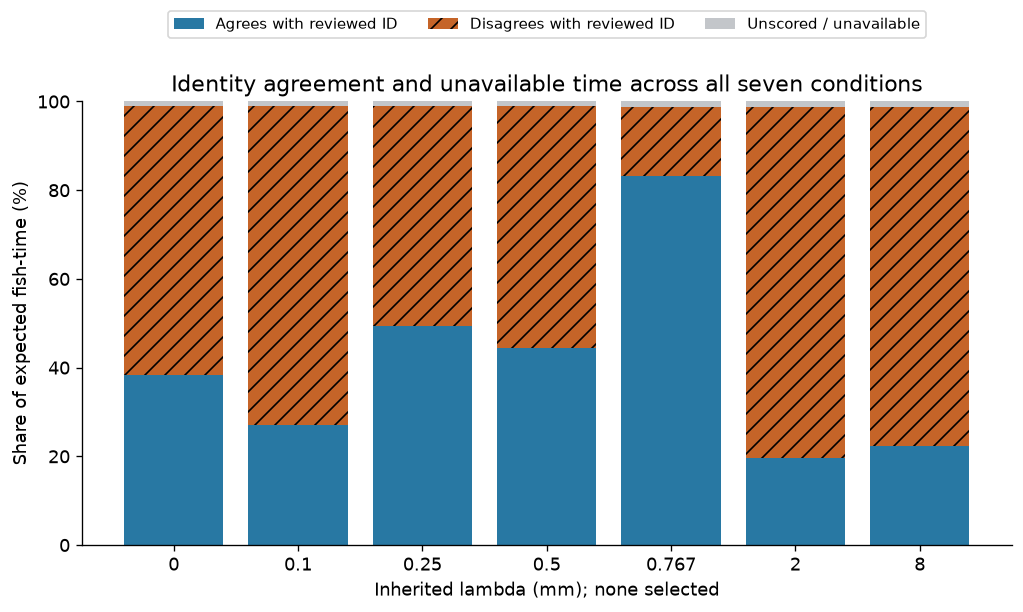

In [4]:
display(
    overview[
        [
            "agreement_percent",
            "scored_time_percent",
            "correct_time_percent",
            "joint_correct_percent",
        ]
    ]
    .rename(
        columns={
            "agreement_percent": "Agreement on scored time (%)",
            "scored_time_percent": "Scored time / expected (%)",
            "correct_time_percent": "Correct ID time / expected (%)",
            "joint_correct_percent": "All three correct / recording time (%)",
        }
    )
    .round(2)
)
fig, ax = plt.subplots(figsize=(10, 4.8))
correct = 100 * overview.correct_seconds / overview.expected_seconds
wrong = 100 * overview.wrong_seconds / overview.expected_seconds
unscored = 100 - correct - wrong
labels = [f"{x:g}" for x in overview.index]
ax.bar(labels, correct, color=colors["correct"], label="Agrees with reviewed ID")
ax.bar(
    labels,
    wrong,
    bottom=correct,
    color=colors["wrong"],
    label="Disagrees with reviewed ID",
    hatch="//",
)
ax.bar(
    labels,
    unscored,
    bottom=correct + wrong,
    color=colors["unscored"],
    label="Unscored / unavailable",
)
ax.set(
    xlabel="Inherited lambda (mm); none selected",
    ylabel="Share of expected fish-time (%)",
    ylim=(0, 100),
    title="Identity agreement and unavailable time across all seven conditions",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=3, fontsize=9)
save_figure(fig, "all_lambda_identity_coverage.png")

## Individual identities at the historical display condition

Coverage uses the complete post-preparation duration for each fish. Agreement uses
only time with an assessable reference, an unambiguous spatial correspondence, and
a supported fixed anchor mapping. Both denominators are necessary.

,Agreement (%),Scored time (%),Correct time / expected (%)
reference_label,,,
F,98.78,98.18,96.98
M1,76.35,98.63,75.30
M2,77.34,99.75,77.15


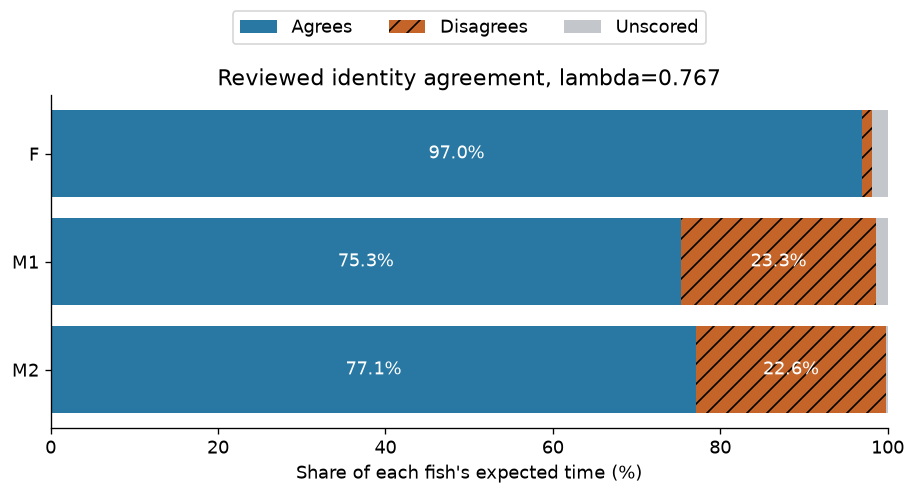

In [5]:
display(
    (
        shown_rows[
            [
                "id_agreement_on_scored_time",
                "scored_time_fraction",
                "correct_id_time_fraction",
            ]
        ]
        * 100
    )
    .rename(
        columns={
            "id_agreement_on_scored_time": "Agreement (%)",
            "scored_time_fraction": "Scored time (%)",
            "correct_id_time_fraction": "Correct time / expected (%)",
        }
    )
    .round(2)
)
fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(3)
parts = [
    ("correct", shown_rows.correct_id_seconds, "Agrees"),
    ("wrong", shown_rows.wrong_id_seconds, "Disagrees"),
    (
        "unscored",
        shown_rows.expected_seconds - shown_rows.correct_id_seconds - shown_rows.wrong_id_seconds,
        "Unscored",
    ),
]
for key, seconds, title in parts:
    values = 100 * seconds.to_numpy() / shown_rows.expected_seconds.to_numpy()
    ax.barh(
        shown_rows.index,
        values,
        left=left,
        color=colors[key],
        label=title,
        hatch="//" if key == "wrong" else None,
    )
    for i, value in enumerate(values):
        if value > 5:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="white",
            )
    left += values
ax.set(
    xlim=(0, 100),
    xlabel="Share of each fish's expected time (%)",
    title=f"Reviewed identity agreement, lambda={shown:g}",
)
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.28), ncol=3)
save_figure(fig, "individual_identity_coverage.png")

## When identity disagreement persists

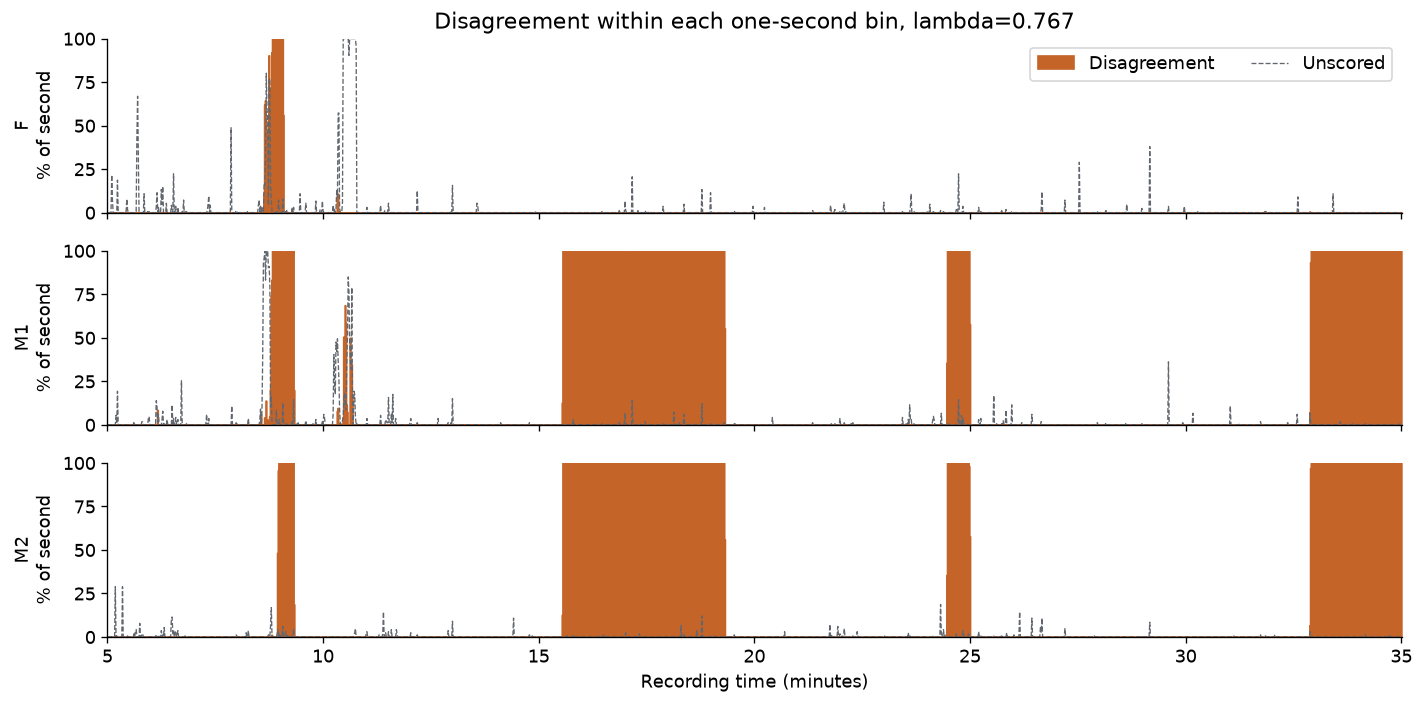

,reference_label,start_frame,stop_frame_exclusive,start_s,stop_s,duration_s
3189,M2,327482,340333,1973.038,2050.464,77.426
3166,M2,172770,182362,1040.917,1098.708,57.791
3132,M1,340334,348325,2050.470,2098.615,48.145
3128,M1,327498,334500,1973.134,2015.321,42.186
3158,M2,157471,164133,948.742,988.880,40.138
3088,M1,157473,164133,948.754,988.880,40.126
3190,M2,340335,345893,2050.476,2083.962,33.486
3161,M2,164489,169537,991.025,1021.439,30.414
3103,M1,173978,178148,1048.195,1073.319,25.124
3112,M1,183066,187118,1102.949,1127.362,24.413


These intervals break at missing or ambiguous observations. They are observed disagreement runs, not a count of independently adjudicated crossings or a guarantee about the gap interiors.

In [6]:
timeline = pd.read_csv(score / "per_second_agreement.csv")
timeline = timeline[timeline.lambda_mm.eq(shown)]
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, label in zip(axes, ["F", "M1", "M2"], strict=True):
    rows = timeline[timeline.reference_label.eq(label)]
    x = rows.recording_second.to_numpy() / 60
    total = rows.observed_bin_seconds.to_numpy()
    wrong = np.divide(rows.wrong_id_seconds, total, out=np.zeros_like(total), where=total > 0) * 100
    unscored = (
        np.divide(
            total - rows.correct_id_seconds - rows.wrong_id_seconds,
            total,
            out=np.zeros_like(total),
            where=total > 0,
        )
        * 100
    )
    ax.fill_between(x, 0, wrong, color=colors["wrong"], step="post", label="Disagreement")
    ax.plot(x, unscored, color="#62676E", linewidth=0.8, label="Unscored", linestyle="--")
    ax.set(ylabel=f"{label}\n% of second", ylim=(0, 100))
axes[0].set_title(f"Disagreement within each one-second bin, lambda={shown:g}")
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set(xlabel="Recording time (minutes)", xlim=(5, inventory["recording_end_s"] / 60))
axes[-1].set_xticks([5, 10, 15, 20, 25, 30, 35])
fig.tight_layout()
save_figure(fig, "identity_disagreement_timeline.png")
intervals = pd.read_csv(score / "wrong_identity_intervals.csv")
display(
    intervals[intervals.lambda_mm.eq(shown)]
    .nlargest(10, "duration_s")[
        [
            "reference_label",
            "start_frame",
            "stop_frame_exclusive",
            "start_s",
            "stop_s",
            "duration_s",
        ]
    ]
    .round(3)
)
display(
    Markdown(
        "These intervals break at missing or ambiguous observations. "
        "They are observed disagreement runs, not a count of independently "
        "adjudicated crossings or a guarantee about the gap interiors."
    )
)

## Which identities are confused

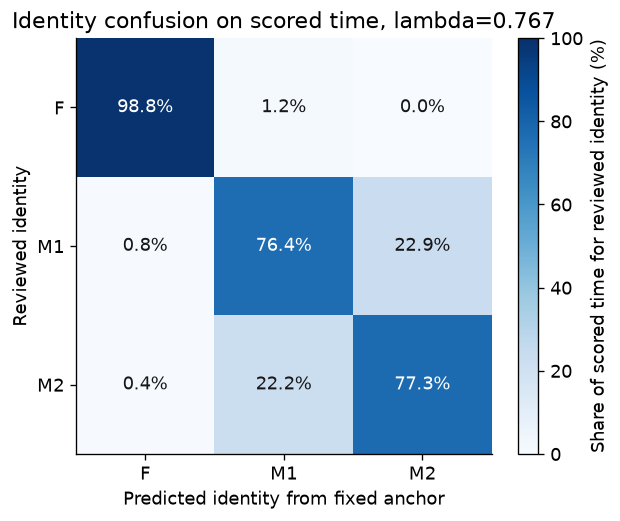

In [7]:
with np.load(score / f"scoring_arrays_lam{shown:g}.npz") as z:
    slots, weights, eligible, mapping = (
        z["matched_slot"],
        z["duration_s"],
        z["eligible"],
        z["anchor_reference_to_slot"],
    )
confusion = np.array(
    [[weights[eligible & (slots[:, i] == mapping[j])].sum() for j in range(3)] for i in range(3)]
)
percent = confusion / confusion.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(5.6, 4.5))
image = ax.imshow(percent, vmin=0, vmax=100, cmap="Blues")
ax.set(
    xticks=range(3),
    yticks=range(3),
    xticklabels=["F", "M1", "M2"],
    yticklabels=["F", "M1", "M2"],
    xlabel="Predicted identity from fixed anchor",
    ylabel="Reviewed identity",
    title=f"Identity confusion on scored time, lambda={shown:g}",
)
for i in range(3):
    for j in range(3):
        ax.text(
            j,
            i,
            f"{percent[i, j]:.1f}%",
            ha="center",
            va="center",
            color="white" if percent[i, j] > 60 else "#171717",
        )
fig.colorbar(image, ax=ax, label="Share of scored time for reviewed identity (%)")
save_figure(fig, "identity_confusion.png")

## Matching sensitivity, fragmentation, and proximity

In [8]:
sensitivity = summary[summary.lambda_mm.eq(shown)].copy()
sensitivity["Agreement (%)"] = sensitivity.id_agreement_on_scored_time * 100
sensitivity["Scored time (%)"] = sensitivity.scored_time_fraction * 100
display(
    sensitivity[["match_distance_mm", "reference_label", "Agreement (%)", "Scored time (%)"]].round(
        3
    )
)
gated = pd.read_csv(score / "gated_local_track_purity.csv")
gated_view = gated[gated.lambda_mm.eq(shown)]
purity = gated_view.majority_seconds.sum() / gated_view.matched_seconds.sum()
display(
    Markdown(
        f"The gated output contains **{len(gated_view)}** local tracks "
        "with assessable post-preparation matches. "
        f"Their retrospective, time-weighted majority-label purity is **{purity:.2%}**. "
        "Many local tracks can map to the same fish in this diagnostic. "
        "This does not establish "
        "consistent identity between fragments and is not trial-wide identity coverage."
    )
)
proximity = pd.read_csv(score / "proximity_context.csv")
display(proximity[proximity.lambda_mm.eq(shown)].round(4))
display(
    Markdown(
        "The 20 mm condition describes geometric proximity, not courtship. "
        "An identity exchange can start during contact and persist after "
        "the fish separate, so time spent with wrong identity is not "
        "the same measure as the risk of an exchange starting in each context."
    )
)

,match_distance_mm,reference_label,Agreement (%),Scored time (%)
36,2.0,F,98.859,97.552
37,2.0,M1,76.317,97.972
38,2.0,M2,77.351,99.288
39,5.0,F,98.776,98.178
40,5.0,M1,76.354,98.626
41,5.0,M2,77.339,99.750
42,10.0,F,98.776,98.240
43,10.0,M1,76.354,98.690
44,10.0,M2,77.346,99.804


The gated output contains **458** local tracks with assessable post-preparation matches. Their retrospective, time-weighted majority-label purity is **99.72%**. Many local tracks can map to the same fish in this diagnostic. This does not establish consistent identity between fragments and is not trial-wide identity coverage.

,lambda_mm,context,fish_seconds,scored_fish_seconds,wrong_fish_seconds,wrong_fraction_of_scored,unscored_fraction
12,0.767,close_20mm,998.8764,978.2353,134.0897,0.1371,0.0207
13,0.767,separated,4308.4677,4305.3409,708.7727,0.1646,0.0007
14,0.767,reference_incomplete,93.4458,55.1879,5.5550,0.1007,0.4094


The 20 mm condition describes geometric proximity, not courtship. An identity exchange can start during contact and persist after the fish separate, so time spent with wrong identity is not the same measure as the risk of an exchange starting in each context.

## Validation and interpretation limits

In [9]:
independent = sum(a["independent_exact_coordinate_checks"] for a in validation["arms"].values())
different = sum(
    v["different_elements"]
    for a in validation["previous_run_array_comparison"].values()
    for v in a.values()
)
display(
    Markdown(
        "Scoring totals reconcile to all expected frames and durations. "
        "A separate scalar audit checked "
        f"**{independent:,}** exact-coordinate correspondences with no scoring discrepancies. "
        f"The raw-slot array comparison found **{different:,}** differing elements "
        "across xyz, source rows, "
        "slot labels, residuals, and view-count arrays (all seven conditions). "
        "This numerical audit does not independently certify "
        "the supplied human identity labels."
    )
)
display(
    pd.DataFrame(
        [
            {
                "lambda_mm": float(lam),
                **{k: v["different_elements"] for k, v in fields.items()},
            }
            for lam, fields in validation["previous_run_array_comparison"].items()
        ]
    )
)
display(
    Markdown(
        "Numeric slot names are arbitrary. The following comparison aligns each run "
        "once using its original [298, 300) s anchor, in F/M1/M2 order, "
        "and compares the post-preparation window. "
        "No mapping is refitted after a crossing. This separates slot renaming "
        "from changes in reviewed identity agreement."
    )
)
aligned_rows = []
for lam, result in validation["anchor_aligned_comparison"].items():
    aligned_rows.append(
        {
            "Lambda": float(lam),
            "Old slots (F/M1/M2)": str(result["previous_reference_to_slot"]),
            "New slots (F/M1/M2)": str(result["rerun_reference_to_slot"]),
            "Changed matched ID (fish-s)": result["changed_identity_fish_seconds_both_matched"],
            "Changed scoring status (rows)": result["changed_score_status_observations"],
            "Max aligned XYZ difference (mm)": result["post_preparation_fields"]["xyz"][
                "max_absolute_difference"
            ],
        }
    )
display(pd.DataFrame(aligned_rows).round(6))
display(
    Markdown(
        "The preserved run used revision 50d56d0 and Python 3.13.17; this run uses "
        "revision c601b7b and Python 3.13.11. Tracked pipeline code is unchanged "
        "between these revisions. Any remaining run differences have not been "
        "causally isolated and are not evidence of a tested method improvement."
    )
)
display(
    Markdown(
        "Use the mismatch intervals and original video to review "
        "consequential male-male joins. If positions remain usable while "
        "identity correspondence fails, compare appearance-based crossing links "
        "on held-out events with geometry fixed. Keep unsupported links unresolved. "
        "No appearance model was trained or evaluated in this run."
    )
)

Scoring totals reconcile to all expected frames and durations. A separate scalar audit checked **19,087** exact-coordinate correspondences with no scoring discrepancies. The raw-slot array comparison found **16,265,637** differing elements across xyz, source rows, slot labels, residuals, and view-count arrays (all seven conditions). This numerical audit does not independently certify the supplied human identity labels.

,lambda_mm,xyz,source,slot_track,residual_mm,n_views_used
0,0.000,1737729,1734941,0,579243,0
1,0.100,3045,2984,0,1015,0
2,0.250,45,40,0,15,0
3,0.500,2092107,2089661,0,697369,0
4,0.767,3137034,3133564,0,1045678,0
5,2.000,1410,1410,0,470,0
6,8.000,3381,3369,0,1127,0


Numeric slot names are arbitrary. The following comparison aligns each run once using its original [298, 300) s anchor, in F/M1/M2 order, and compares the post-preparation window. No mapping is refitted after a crossing. This separates slot renaming from changes in reviewed identity agreement.

,Lambda,Old slots (F/M1/M2),New slots (F/M1/M2),Changed matched ID (fish-s),Changed scoring status (rows),Max aligned XYZ difference (mm)
0,0.000,"[2, 1, 0]","[2, 1, 0]",3447.062077,381165,187.099854
1,0.100,"[0, 1, 2]","[0, 1, 2]",0.000000,0,0.000000
2,0.250,"[1, 2, 0]","[1, 2, 0]",0.000000,0,0.000000
3,0.500,"[2, 1, 0]","[1, 2, 0]",0.000000,0,0.000000
4,0.767,"[2, 0, 1]","[0, 1, 2]",0.000000,0,0.000000
5,2.000,"[1, 2, 0]","[1, 2, 0]",0.000000,0,0.000000
6,8.000,"[2, 1, 0]","[2, 1, 0]",0.000000,0,0.000000


The preserved run used revision 50d56d0 and Python 3.13.17; this run uses revision c601b7b and Python 3.13.11. Tracked pipeline code is unchanged between these revisions. Any remaining run differences have not been causally isolated and are not evidence of a tested method improvement.

Use the mismatch intervals and original video to review consequential male-male joins. If positions remain usable while identity correspondence fails, compare appearance-based crossing links on held-out events with geometry fixed. Keep unsupported links unresolved. No appearance model was trained or evaluated in this run.

## Implementation concern to isolate before changing the method

A separate observation-only audit ran the unchanged C24 tracker on the first
2,000 frames per camera. In the top view at frame 20, the library returned
input rows in order `[0, 1, 2, 4, 3, 5]`. The repository adapter writes labels
by returned-list offset, so two labels were written to the wrong detection
rows. No return-order mismatch was observed in the two side-view prefixes.

This is an adapter row-correspondence defect, not evidence that appearance
features are necessary. The short prefix is outside the scored window and
does not quantify its contribution to later ID disagreement. This rerun
deliberately preserves the existing implementation to measure the current
baseline. A separately versioned repair and comparison should precede any
conclusion that the remaining error is an inherent geometry limitation.
Audit code, exact frames, and evidence are in `tracker_order_audit_2000frames`.

An extended top-camera audit ran continuously from frame zero through 51,999.
It found only the same frame-20 case and no return-order mismatch in its
2,206 post-preparation frames. This is not a full-trial audit and does not
establish this defect as the cause of the measured ID disagreements.
Extended evidence is in `tracker_order_audit_52000frames_top_cam`.

## Files and safe use

`automatic_pectoral_3d_lam*.csv.gz` contains the uncorrected automatic positions,
original slot labels, local gated track IDs, and fixed-anchor predicted names.
**These predicted names are not certified trial-wide identities.** The
`identity_support` column explicitly marks them `automatic_unvalidated`.
Raw stage arrays retain source-camera row mappings. Scoring arrays and tables
record agreement, disagreement, and unassessed time separately.

The source review, prior outputs, and existing repository edits were preserved.
Input hashes, annotation archive location, timing audit, code snapshots,
stage logs, and provenance are stored beside the generated results.